# Metadata and Cold-Start Recommendation

Notebook 10 compared the models using interactions only. This notebook asks whether product metadata (titles, descriptions and categories, encoded in Notebook 07) improves recommendation performance.

Only LightGCN is carried forward. NGCF and GraphSAGE both underperformed matrix factorisation in the collaborative setting, so adding metadata to them would not change the main comparison. GraphSAGE appears only in the cold-start experiment, where its feature aggregation is most relevant.

Three questions are addressed:

1. **Does metadata help?** Compare LightGCN with and without BLaIR features under both protocols. The feature projection is initialised at zero, so both models start identically and any difference is due to the metadata.
2. **Does the encoder matter?** Compare BLaIR with MiniLM and TF-IDF+SVD to test whether domain-specific pre-training provides an advantage.
3. **Does metadata help cold items?** Items unseen during training have no learned ID embedding, making metadata their only source of information.

Everything else is inherited from Notebook 10: the same subset, splits, graphs, evaluators, training loop and selected hyperparameters.

## 1. Imports and configuration

In [9]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import evaluation as ev
from src import features as ft
from src import graph as gr
from src import models as md
from src import training as tr

# Paths
SUBSETS_DIR = PROJECT_ROOT / "data" / "processed" / "subsets_earliest"
FEATURES_DIR = PROJECT_ROOT / "data" / "processed" / "features_earliest"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
CACHE = RESULTS_DIR / "11_runs"

for directory in (RESULTS_DIR, FIGURES_DIR, CACHE):
    directory.mkdir(parents=True, exist_ok=True)

# Experiment config, identical to Notebook 10
SUBSET = "small"
PROTOCOLS = ["last_out", "timestamp"]
K_VALUES = [10, 20]
EVAL_BATCH_USERS = 1024

SEEDS = [42, 1, 2]
SEED = SEEDS[0]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DIM = 32
LR = 1e-3
BATCH = 8192
SAMPLING = "user"
EPOCHS = 300

ENCODERS = ["blair", "minilm", "tfidf_svd"]

# selected in Notebook 10, carried forward unchanged
LIGHTGCN_BEST = {
    "last_out":  {"n_layers": 3, "l2_reg": 3e-3},
    "timestamp": {"n_layers": 3, "l2_reg": 3e-4},
}

# Notebook 10 test results, for comparison
NO_FEATURES = {
    "last_out":  {"ndcg@10": 0.00812, "std": 0.00007},
    "timestamp": {"ndcg@10": 0.00158, "std": 0.00020},
}

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"device: {DEVICE}")
print(f"subset: {SUBSET}, protocols: {PROTOCOLS}, seeds: {SEEDS}")
print(f"encoders: {ENCODERS}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cuda
subset: small, protocols: ['last_out', 'timestamp'], seeds: [42, 1, 2]
encoders: ['blair', 'minilm', 'tfidf_svd']


## 2. Data, graphs, evaluators and features

The setup below Notebook 10's setup unchanged (same splits, same graphs, same
evaluators) so that the feature and no-feature arms are comparable without
qualification.

The new part is the feature matrices. Notebook 07 built these for every item in the
subset, including items that never appear in training, which is what makes the cold-start
experiment possible: a cold item has no useful ID embedding but it does have a
description.

In [10]:
def load_protocol(subset, protocol):
    base = SUBSETS_DIR / subset
    splits = base / "splits" / protocol
    parts = {
        name: pq.read_table(splits / f"{name}.parquet",
                            columns=["user_idx", "item_idx"]).to_pandas()
        for name in ["train", "validation", "test"]
    }
    return {
        "protocol": protocol,
        "n_users": len(pq.read_table(base / "user_mapping.parquet")),
        "n_items": len(pq.read_table(base / "item_mapping.parquet")),
        "eval_users": pq.read_table(
            splits / "eval_users.parquet").to_pandas()["user_idx"].to_numpy(),
        "cold_items": pq.read_table(
            splits / "cold_items.parquet").to_pandas()["item_idx"].to_numpy(),
        **parts,
    }


data = {p: load_protocol(SUBSET, p) for p in PROTOCOLS}

pd.DataFrame([{
    "protocol": p,
    "users": d["n_users"], "items": d["n_items"],
    "train": len(d["train"]), "validation": len(d["validation"]), "test": len(d["test"]),
    "eval_users": len(d["eval_users"]), "cold_items": len(d["cold_items"]),
} for p, d in data.items()])

,protocol,users,items,train,validation,test,eval_users,cold_items
0,last_out,258597,105298,1829582,258597,258597,50000,425
1,timestamp,258597,105298,2020041,165504,161231,50000,8353


In [11]:
graphs = {}
for protocol, d in data.items():
    n_nodes = d["n_users"] + d["n_items"]
    edge_index = gr.build_edge_index(d["train"], d["n_users"], d["n_items"])

    symmetric = gr.normalised_adjacency(edge_index, n_nodes, device=DEVICE)
    radius, iterations = gr.spectral_radius(symmetric)

    leaked = (gr.count_held_out_edges(edge_index, d["validation"], d["n_users"])
              + gr.count_held_out_edges(edge_index, d["test"], d["n_users"]))

    graphs[protocol] = {
        "edge_index": edge_index,
        "n_nodes": n_nodes,
        "symmetric": symmetric.to_sparse_csr(),
        "mean": gr.mean_adjacency(edge_index, n_nodes, device=DEVICE).to_sparse_csr(),
    }

    print(f"{protocol}: {edge_index.shape[1] // 2:,} edges over {n_nodes:,} nodes | "
          f"symmetric {gr.verify_symmetry(edge_index)} | "
          f"spectral radius {radius:.6f} ({iterations} it) | held-out edges {leaked}")

    assert leaked == 0
    assert abs(radius - 1.0) < 1e-3

c:\Projects\gnn-recommender-dissertation\src\graph.py:78: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  adj = torch.sparse_coo_tensor(
C:\Users\xhani\AppData\Local\Temp\ipykernel_16484\1024560151.py:15: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\SparseCsrTensorImpl.cpp:51.)
  "symmetric": symmetric.to_sparse_csr(),


last_out: 1,829,582 edges over 363,895 nodes | symmetric True | spectral radius 1.000000 (43 it) | held-out edges 0
timestamp: 2,020,041 edges over 363,895 nodes | symmetric True | spectral radius 1.000000 (31 it) | held-out edges 0


In [12]:
test_evaluators, val_evaluators, tune_evaluators = {}, {}, {}

for protocol, d in data.items():
    test_evaluators[protocol] = ev.Evaluator.from_frames(
        ground_truth=d["test"],
        mask_frames=[d["train"], d["validation"]],
        eval_users=d["eval_users"],
        n_users=d["n_users"], n_items=d["n_items"],
        k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
    )

    probe = ev.Evaluator.from_frames(
        ground_truth=d["validation"], mask_frames=[d["train"]],
        eval_users=d["eval_users"], n_users=d["n_users"], n_items=d["n_items"],
        k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
    )
    usable = d["eval_users"][np.diff(probe.truth_indptr)[d["eval_users"]] > 0]

    for store, users in [(val_evaluators, usable), (tune_evaluators, usable[:10_000])]:
        store[protocol] = ev.Evaluator.from_frames(
            ground_truth=d["validation"], mask_frames=[d["train"]],
            eval_users=users, n_users=d["n_users"], n_items=d["n_items"],
            k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
        )

    print(f"{protocol}: test {len(d['eval_users']):,} users | "
          f"validation {len(usable):,} | tuning {len(tune_evaluators[protocol].eval_users):,}")

last_out: test 50,000 users | validation 50,000 | tuning 10,000
timestamp: test 50,000 users | validation 24,514 | tuning 10,000


In [13]:
features = {enc: ft.load_item_features(FEATURES_DIR, SUBSETS_DIR, SUBSET, encoder=enc)
            for enc in ENCODERS}

n_items = data["last_out"]["n_items"]
rows = []
for enc, matrix in features.items():
    assert matrix.shape[0] == n_items, f"{enc}: {matrix.shape[0]} rows, expected {n_items}"
    rows.append({"encoder": enc, "dimensions": matrix.shape[1],
                 "mean": float(matrix.mean()), "std": float(matrix.std()),
                 "all-zero rows": int((np.abs(matrix).sum(axis=1) == 0).sum())})

pd.DataFrame(rows)

,encoder,dimensions,mean,std,all-zero rows
0,blair,807,0.001247,0.049767,0
1,minilm,423,0.002407,0.068719,0
2,tfidf_svd,295,0.003276,0.082274,0


In [14]:
def build_lightgcn(protocol, encoder=None, seed=SEED, n_layers=None):
    """LightGCN at the Notebook 10 configuration, optionally with item features."""
    d, cfg = data[protocol], LIGHTGCN_BEST[protocol]
    return md.LightGCN(
        d["n_users"], d["n_items"], dim=DIM, seed=seed,
        item_features=None if encoder is None else features[encoder],
        adjacency=graphs[protocol]["symmetric"],
        n_layers=cfg["n_layers"] if n_layers is None else n_layers,
    )

## 3. Regularisation with features

The feature projection adds 25,824 parameters to a model with 11.6 million, so the
optimal regularisation might reasonably be expected not to move. Instead, it falls by one to two orders of magnitude.

Values around the Notebook 10 optimum are evaluated on both protocols using one seed,
with the feature-free results reused from Notebook 10 so the comparison is direct. The
optimum falls from 3e-3 to 1e-4 under leave-last-out and from 3e-4 to 3e-5 under
timestamp, because the features carry real signal and the model relies less on memorising
IDs. Reusing the feature-free value would have reported a 2% gain instead of 15%.

In [55]:
CACHE_10 = RESULTS_DIR / "10_tuning"


def tune_run(protocol, encoder, l2_reg, seed=SEED, epochs=EPOCHS):
    """Train against the tuning evaluator, cached to disk."""
    enc = encoder or "none"
    tag = f"tune_{protocol}_{enc}_reg{l2_reg:g}_e{epochs}_s{seed}"
    path = CACHE / f"{tag}.csv"

    if path.exists():
        history = pd.read_csv(path)
    else:
        t0 = time.time()
        outcome = tr.train_bpr(
            build_lightgcn(protocol, encoder, seed),
            data[protocol]["train"], data[protocol]["n_items"],
            evaluator=tune_evaluators[protocol],
            epochs=epochs, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
            sampling=SAMPLING, patience=10, eval_every=10,
            selection_metric="ndcg@10", device=DEVICE, seed=seed, verbose=False,
        )
        history = outcome["history"]
        history.to_csv(path, index=False)
        print(f"  {tag}: {(time.time() - t0) / 60:.1f} min", flush=True)

    evaluated = history.dropna(subset=["val_ndcg@10"])
    best = evaluated.loc[evaluated["val_ndcg@10"].idxmax()]
    return {"protocol": protocol, "encoder": enc, "l2_reg": l2_reg, "seed": seed,
            "best_epoch": int(best["epoch"]),
            "val_ndcg@10": float(best["val_ndcg@10"]),
            "epochs_run": len(history)}


def notebook10_run(protocol, l2_reg, n_layers=3, seed=SEED):
    """Read the matching feature-free run from Notebook 10's cache."""
    path = CACHE_10 / f"LightGCN_{protocol}_L{n_layers}_reg{l2_reg:g}_e300_s{seed}.csv"
    evaluated = pd.read_csv(path).dropna(subset=["val_ndcg@10"])
    best = evaluated.loc[evaluated["val_ndcg@10"].idxmax()]
    return {"protocol": protocol, "encoder": "none", "l2_reg": l2_reg, "seed": seed,
            "best_epoch": int(best["epoch"]),
            "val_ndcg@10": float(best["val_ndcg@10"]),
            "epochs_run": len(pd.read_csv(path))}

In [56]:
reg_check = pd.DataFrame(
    [notebook10_run("last_out", reg) for reg in [3e-4, 1e-3, 3e-3, 1e-2]]
    + [tune_run("last_out", "blair", reg)
       for reg in [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]]
)
reg_check.pivot(index="l2_reg", columns="encoder", values="val_ndcg@10")

encoder,blair,none
l2_reg,,
0.0001,0.014711,NaN
0.0003,0.014607,0.011862
0.0010,0.013894,0.012407
0.0030,0.012991,0.012740
0.0100,0.011956,0.011910


In [57]:
reg_check[reg_check.encoder == "blair"][
    ["l2_reg", "best_epoch", "val_ndcg@10", "epochs_run"]]

,l2_reg,best_epoch,val_ndcg@10,epochs_run
4,0.0001,220,0.014711,300
5,0.0003,220,0.014607,300
6,0.0010,300,0.013894,300
7,0.0030,300,0.012991,300
8,0.0100,290,0.011956,300


In [58]:
reg_check_ts = pd.DataFrame(
    [notebook10_run("timestamp", reg) for reg in [1e-4, 3e-4, 1e-3]]
    + [tune_run("timestamp", "blair", reg) for reg in [3e-5, 1e-4, 3e-4]]
)
reg_check_ts.pivot(index="l2_reg", columns="encoder", values="val_ndcg@10")

encoder,blair,none
l2_reg,,
0.00003,0.006142,NaN
0.00010,0.006027,0.005264
0.00030,0.005868,0.005309
0.00100,NaN,0.005178


The low-regularisation runs were checked for overfitting: all five
ran the full 300 epochs without early stopping, and the best peaked at epoch 220, so the
improvement is real convergence rather than a model memorising and being caught early.

Selected: 1e-4 under leave-last-out and 3e-5 under timestamp. 

## 4. Does metadata help?

LightGCN with BLaIR features is compared against the feature-free model under both protocols using three seeds. The feature-free results are reused from Notebook 10, where the same splits, evaluators, training loop and seeds were used.

Each model uses its own selected regularisation. Reusing the feature-free value would underestimate the effect of metadata, as shown in the tuning section.

Per-user scores are saved for the significance tests in Notebook 12.

In [59]:
FINAL_CACHE = RESULTS_DIR / "11_final"
FINAL_CACHE.mkdir(exist_ok=True)
FINAL_CACHE_10 = RESULTS_DIR / "10_final"

FEATURE_REG = {"last_out": 1e-4, "timestamp": 3e-5}


def final_run(protocol, encoder, l2_reg, seed):
    """Train at the selected configuration and evaluate once on test."""
    enc = encoder or "none"
    tag = f"LightGCN_{enc}_{protocol}_s{seed}"
    summary_path = FINAL_CACHE / f"{tag}.json"

    if summary_path.exists():
        with open(summary_path) as fh:
            return {**json.load(fh), "cached": True}

    t0 = time.time()
    outcome = tr.train_bpr(
        build_lightgcn(protocol, encoder, seed),
        data[protocol]["train"], data[protocol]["n_items"],
        evaluator=val_evaluators[protocol],
        epochs=EPOCHS, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
        sampling=SAMPLING, patience=10, eval_every=10, selection_metric="ndcg@10",
        device=DEVICE, seed=seed, verbose=False,
    )

    scored = test_evaluators[protocol].evaluate(outcome["model"].score_fn(),
                                                return_per_user=True)
    np.savez_compressed(FINAL_CACHE / f"{tag}.npz", **scored["per_user"])

    summary = {"model": "LightGCN", "encoder": enc, "protocol": protocol, "seed": seed,
               "l2_reg": l2_reg, "best_epoch": outcome["best_epoch"],
               "val_ndcg@10": float(outcome["best_val_score"]),
               "minutes": (time.time() - t0) / 60, **scored["means"]}
    with open(summary_path, "w") as fh:
        json.dump(summary, fh)

    print(f"  {tag}: {summary['minutes']:.1f} min, test ndcg@10 {summary['ndcg@10']:.5f}",
          flush=True)
    return {**summary, "cached": False}


def notebook10_final(protocol, seed):
    """The feature-free arm, from Notebook 10's saved results."""
    with open(FINAL_CACHE_10 / f"LightGCN_{protocol}_s{seed}.json") as fh:
        summary = json.load(fh)
    return {**summary, "encoder": "none",
            "l2_reg": LIGHTGCN_BEST[protocol]["l2_reg"], "cached": True}

In [60]:
main_results = pd.DataFrame(
    [notebook10_final(p, s) for p in PROTOCOLS for s in SEEDS]
    + [final_run(p, "blair", FEATURE_REG[p], s) for p in PROTOCOLS for s in SEEDS]
)
main_results.to_csv(RESULTS_DIR / "11_main_comparison.csv", index=False)

summary = (main_results.groupby(["protocol", "encoder"])["ndcg@10"]
           .agg(["mean", "std"]).round(5))
print(summary.to_string())

for protocol in PROTOCOLS:
    with_f = main_results.query("protocol == @protocol and encoder == 'blair'")["ndcg@10"].mean()
    without = main_results.query("protocol == @protocol and encoder == 'none'")["ndcg@10"].mean()
    print(f"\n{protocol}: {without:.5f} -> {with_f:.5f}  ({with_f / without - 1:+.1%})")

                      mean      std
protocol  encoder                  
last_out  blair    0.00864  0.00011
          none     0.00812  0.00007
timestamp blair    0.00230  0.00007
          none     0.00158  0.00020

last_out: 0.00812 -> 0.00864  (+6.3%)

timestamp: 0.00158 -> 0.00230  (+45.9%)


In [61]:
# The feature-free LightGCN arm comes from Notebook 10 at its own regularisation
# (3e-3 / 3e-4) while the feature arm runs at FEATURE_REG (1e-4 / 3e-5), so the
# pair differs in regularisation and in notebook as well as in features. Rerun
# the feature-free arm here so only the features change.

rows = []
for protocol, reg in FEATURE_REG.items():
    for seed in SEEDS:
        with_f  = final_run(protocol, "blair", reg, seed)
        without = final_run(protocol, None,    reg, seed)
        rows.append({"protocol": protocol, "seed": seed, "l2_reg": reg,
                     "without": without["ndcg@10"], "with BLaIR": with_f["ndcg@10"],
                     "change": with_f["ndcg@10"] / without["ndcg@10"] - 1})

lgcn_matched = pd.DataFrame(rows)
print(lgcn_matched.to_string(index=False))
print()
print(lgcn_matched.groupby("protocol")
      .agg(change_mean=("change", "mean"), change_sd=("change", "std"))
      .to_string())

 protocol  seed  l2_reg  without  with BLaIR   change
 last_out    42 0.00010 0.007696    0.008719 0.132836
 last_out     1 0.00010 0.007376    0.008506 0.153167
 last_out     2 0.00010 0.007704    0.008681 0.126730
timestamp    42 0.00003 0.001436    0.002368 0.649796
timestamp     1 0.00003 0.001413    0.002290 0.621110
timestamp     2 0.00003 0.001516    0.002237 0.475626

           change_mean  change_sd
protocol                         
last_out      0.137578   0.013842
timestamp     0.582177   0.093384


Features improve LightGCN by 6.3% under leave-last-out and 45.9% under timestamp, with no
overlap between the seed ranges in either case. These figures compare each arm at its own
selected regularisation. Section 8 repeats the comparison with regularisation held equal
across both arms, where the effects become 13.8% and 58.2%.

## 5. Is the benefit specific to the graph?

Section 4 shows that metadata improves LightGCN. This section asks whether that gain comes from graph propagation or simply from adding item features.

Matrix factorisation provides the control. LightGCN with zero propagation layers is exactly matrix factorisation, as verified in Notebook 09, and both models use the same feature integration. This makes the comparison controlled, with propagation as the only difference.

Two comparisons are reported: one using the regularisation selected for the feature-free model, and one using the regularisation selected after adding metadata.

In [62]:
def mf_run(protocol, encoder, l2_reg, seed=SEED, epochs=EPOCHS, on_test=False):
    """LightGCN with zero layers, which is matrix factorisation. Checkpoint settings
    match Notebook 10's BPR-MF, since that is the arm being compared against."""
    enc = encoder or "none"
    tag = f"MF_{enc}_{protocol}_reg{l2_reg:g}_s{seed}" + ("_test" if on_test else "")
    path = CACHE / f"{tag}.json"

    if path.exists():
        with open(path) as fh:
            return {**json.load(fh), "cached": True}

    t0 = time.time()
    outcome = tr.train_bpr(
        build_lightgcn(protocol, encoder, seed, n_layers=0),
        data[protocol]["train"], data[protocol]["n_items"],
        evaluator=val_evaluators[protocol] if on_test else tune_evaluators[protocol],
        epochs=epochs, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
        sampling=SAMPLING, patience=50, eval_every=2, selection_metric="ndcg@10",
        device=DEVICE, seed=seed, verbose=False,
    )

    result = {"encoder": enc, "protocol": protocol, "l2_reg": l2_reg, "seed": seed,
              "best_epoch": outcome["best_epoch"],
              "val_ndcg@10": float(outcome["best_val_score"]),
              "minutes": (time.time() - t0) / 60}

    if on_test:
        scored = test_evaluators[protocol].evaluate(outcome["model"].score_fn(),
                                                    return_per_user=True)
        np.savez_compressed(CACHE / f"{tag}.npz", **scored["per_user"])
        result.update(scored["means"])

    with open(path, "w") as fh:
        json.dump(result, fh)
    print(f"  {tag}: {result['minutes']:.1f} min", flush=True)
    return {**result, "cached": False}


def mean_over_seeds(load):
    return float(np.mean([load(s) for s in SEEDS]))


def mf_without(protocol):
    """BPR-MF without features, from Notebook 10, averaged over the same seeds used here.
    Notebook 10 reports BPR-MF over five seeds; this notebook trains three, so the
    baseline is restricted to those three to keep the comparison like for like."""
    return mean_over_seeds(lambda s: json.load(
        open(FINAL_CACHE_10 / f"BPR-MF_{protocol}_s{s}.json"))["ndcg@10"])

In [63]:
mf_sweep = pd.DataFrame([
    mf_run("last_out", "blair", reg) for reg in [1e-3, 1e-2, 1e-1]
])
mf_sweep[["l2_reg", "best_epoch", "val_ndcg@10"]]

,l2_reg,best_epoch,val_ndcg@10
0,0.001,276,0.010792
1,0.010,222,0.010485
2,0.100,108,0.008735


In [64]:
mf_best_reg = float(mf_sweep.loc[mf_sweep["val_ndcg@10"].idxmax(), "l2_reg"])

mf_features = pd.DataFrame([
    mf_run("last_out", "blair", mf_best_reg, s, on_test=True) for s in SEEDS
])

base = mf_without("last_out")
print(f"MF + BLaIR : {mf_features['ndcg@10'].mean():.5f}   (reg {mf_best_reg:g})")
print(f"MF alone   : {base:.5f}   (Notebook 10, reg 0.10, same {len(SEEDS)} seeds)")
print(f"change     : {mf_features['ndcg@10'].mean() / base - 1:+.1%}")

MF + BLaIR : 0.00491   (reg 0.001)
MF alone   : 0.00630   (Notebook 10, reg 0.10, same 3 seeds)
change     : -22.1%


−22.1% is tuned against tuned. Matrix factorisation with features was given its own regularisation sweep, which selected 1e-3 on validation. At that setting it scores 0.00491 on test, against 0.00630 for matrix factorisation alone at its own optimum of 0.10.

Both sides average the same three seeds. Notebook 10 reports BPR-MF at 0.00641 because it was run with five seeds there; using that number here would compare a five-seed baseline against a three-seed feature model.

In [65]:
base = mf_without("last_out")
mf_matched = pd.DataFrame([
    mf_run("last_out", "blair", 0.10, s, on_test=True) for s in SEEDS
])

print(f"MF + BLaIR at reg 0.10 : {mf_matched['ndcg@10'].mean():.5f}")
print(f"MF alone   at reg 0.10 : {base:.5f}")
print(f"change                 : {mf_matched['ndcg@10'].mean() / base - 1:+.1%}")

MF + BLaIR at reg 0.10 : 0.00574
MF alone   at reg 0.10 : 0.00630
change                 : -8.9%


At matched regularisation of 0.10 the feature model scores 0.00574 against 0.00630, an
8.9% loss, which isolates the effect of the features.

In [66]:
mf_sweep_ts = pd.DataFrame([
    mf_run("timestamp", "blair", reg) for reg in [1e-2, 1e-1, 0.15, 0.3]
])
print(mf_sweep_ts[["l2_reg", "best_epoch", "val_ndcg@10"]].to_string(index=False))

# 0.15 is both the sweep winner here and the value matrix factorisation selected
# without features in Notebook 10, so the matched and tuned comparisons coincide
mf_ts = pd.DataFrame([
    mf_run("timestamp", "blair", 0.15, s, on_test=True) for s in SEEDS
])
base_ts = mf_without("timestamp")
print(f"\nMF + BLaIR at reg 0.15 : {mf_ts['ndcg@10'].mean():.5f}")
print(f"MF alone   at reg 0.15 : {base_ts:.5f}   (Notebook 10, same {len(SEEDS)} seeds)")
print(f"change                 : {mf_ts['ndcg@10'].mean() / base_ts - 1:+.1%}")

 l2_reg  best_epoch  val_ndcg@10
   0.01         216     0.004440
   0.10          10     0.007632
   0.15          28     0.008701
   0.30         122     0.000149

MF + BLaIR at reg 0.15 : 0.00422
MF alone   at reg 0.15 : 0.00454   (Notebook 10, same 3 seeds)
change                 : -7.0%


Under timestamp, the sweep selects 0.15, the same regularisation used by matrix factorisation without features, so the matched and tuned comparisons are identical. Adding features reduces performance by 7.0%, suggesting that matrix factorisation does not benefit from the metadata in this setting.

## 6. Does the encoder matter?

BLaIR was pre-trained by the dataset authors on Amazon product metadata. This experiment tests whether that domain-specific pre-training provides an advantage over a general-purpose sentence encoder (MiniLM) and a statistical baseline (TF-IDF + SVD).

This is a supporting experiment rather than the main contribution, so it is run under leave-last-out with one seed. Each encoder is tuned separately, since the feature matrices have different scales and therefore require different levels of regularisation.

In [67]:
encoder_tuning = pd.DataFrame([
    tune_run("last_out", enc, reg)
    for enc in ENCODERS
    for reg in [1e-4, 3e-4]
])
encoder_tuning.pivot(index="l2_reg", columns="encoder", values="val_ndcg@10")

encoder,blair,minilm,tfidf_svd
l2_reg,,,
0.0001,0.014711,0.014030,0.014281
0.0003,0.014607,0.014349,0.014030


In [68]:
best_reg = (encoder_tuning.loc[encoder_tuning.groupby("encoder")["val_ndcg@10"].idxmax()]
            .set_index("encoder")["l2_reg"].to_dict())
print("selected regularisation:", best_reg)

encoder_results = pd.DataFrame([
    final_run("last_out", enc, best_reg[enc], SEED) for enc in ENCODERS
])

baseline = main_results.query("protocol == 'last_out' and encoder == 'none' and seed == @SEED"
                              )["ndcg@10"].iloc[0]
encoder_results["vs no features"] = encoder_results["ndcg@10"] / baseline - 1

print(f"\nno features (seed {SEED}): {baseline:.5f}\n")
print(encoder_results[["encoder", "l2_reg", "best_epoch", "ndcg@10", "vs no features"]]
      .to_string(index=False, float_format="%.5f"))

selected regularisation: {'blair': 0.0001, 'minilm': 0.0003, 'tfidf_svd': 0.0001}

no features (seed 42): 0.00811

  encoder  l2_reg  best_epoch  ndcg@10  vs no features
    blair 0.00010         110  0.00872         0.07572
   minilm 0.00030         130  0.00873         0.07706
tfidf_svd 0.00010         120  0.00857         0.05681


In [69]:
show = encoder_results[["encoder", "l2_reg", "best_epoch", "ndcg@10"]].copy()
show["vs no features"] = (encoder_results["ndcg@10"] / baseline - 1).map("{:+.1%}".format)
print(f"no features (seed {SEED}): {baseline:.5f}\n")
print(show.to_string(index=False, float_format="%.5f"))

no features (seed 42): 0.00811

  encoder  l2_reg  best_epoch  ndcg@10 vs no features
    blair 0.00010         110  0.00872          +7.6%
   minilm 0.00030         130  0.00873          +7.7%
tfidf_svd 0.00010         120  0.00857          +5.7%


The three encoders perform very similarly, with NDCG@10 ranging from 0.00857 to 0.00873. The differences are small relative to the variation across BLaIR seeds, suggesting that domain-specific pre-training provides no clear advantage over MiniLM in this experiment. Even the simpler TF-IDF+SVD representation captures relevant improvement from adding metadata

## 7. GraphSAGE with features

GraphSAGE is included because, unlike the other models, it builds item representations directly from features rather than relying solely on learned ID embeddings. That property should be most valuable for cold items.

Notebook 10 showed that GraphSAGE is not competitive in the collaborative setting, so it is not included in the main comparison. However, evaluating its feature-based representation is important to test the reason it was included in the project.

This experiment is deliberately limited to leave-last-out, one seed and two regularisation values. The goal is to produce a feature-enabled model for the cold-start evaluation and determine whether GraphSAGE's feature aggregation offers any advantage over LightGCN's feature projection.

In [20]:
def build_graphsage(protocol, encoder=None, seed=SEED, n_layers=3):
    """GraphSAGE at the Notebook 10 configuration, optionally with item features."""
    d = data[protocol]
    return md.GraphSAGE(
        d["n_users"], d["n_items"], dim=DIM, seed=seed,
        item_features=None if encoder is None else features[encoder],
        adjacency=graphs[protocol]["mean"], n_layers=n_layers,
        normalise_output=False, final_activation=True,
    )


def sage_run(protocol, encoder, l2_reg, seed=SEED, on_test=False):
    enc = encoder or "none"
    tag = f"SAGE_{enc}_{protocol}_reg{l2_reg:g}_s{seed}" + ("_test" if on_test else "")
    path = CACHE / f"{tag}.json"

    if path.exists():
        with open(path) as fh:
            return {**json.load(fh), "cached": True}

    t0 = time.time()
    outcome = tr.train_bpr(
        build_graphsage(protocol, encoder, seed),
        data[protocol]["train"], data[protocol]["n_items"],
        evaluator=val_evaluators[protocol] if on_test else tune_evaluators[protocol],
        epochs=EPOCHS, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
        sampling=SAMPLING, patience=10, eval_every=10, selection_metric="ndcg@10",
        device=DEVICE, seed=seed, verbose=False,
    )

    result = {"model": "GraphSAGE", "encoder": enc, "protocol": protocol,
              "l2_reg": l2_reg, "seed": seed, "best_epoch": outcome["best_epoch"],
              "val_ndcg@10": float(outcome["best_val_score"]),
              "minutes": (time.time() - t0) / 60}

    if on_test:
        scored = test_evaluators[protocol].evaluate(outcome["model"].score_fn(),
                                                    return_per_user=True)
        np.savez_compressed(CACHE / f"{tag}.npz", **scored["per_user"])
        result.update(scored["means"])

    with open(path, "w") as fh:
        json.dump(result, fh)
    print(f"  {tag}: {result['minutes']:.1f} min", flush=True)
    return {**result, "cached": False}

In [71]:
# 3e-3 is its Notebook 10 setting; 1e-4 is where LightGCN's optimum moved once
# features were added, so the two bracket the plausible range
sage_sweep = pd.DataFrame([
    sage_run("last_out", "blair", reg) for reg in [1e-4, 3e-3]
])
print(sage_sweep[["l2_reg", "best_epoch", "val_ndcg@10"]].to_string(index=False))

sage_best_reg = float(sage_sweep.loc[sage_sweep["val_ndcg@10"].idxmax(), "l2_reg"])
sage_features = sage_run("last_out", "blair", sage_best_reg, SEED, on_test=True)

print(f"\nGraphSAGE + BLaIR : {sage_features['ndcg@10']:.5f}   (reg {sage_best_reg:g})")
print(f"GraphSAGE alone   : 0.00445   (Notebook 10, seed 42)")
print(f"LightGCN + BLaIR  : 0.00872   (seed 42)")

 l2_reg  best_epoch  val_ndcg@10
 0.0001          10     0.008995
 0.0030          30     0.008460

GraphSAGE + BLaIR : 0.00537   (reg 0.0001)
GraphSAGE alone   : 0.00445   (Notebook 10, seed 42)
LightGCN + BLaIR  : 0.00872   (seed 42)


In [72]:
# Job 1: matched-regularisation pairs under both protocols.
# Cell 34 compares the feature run at 1e-4 against the Notebook 10 run at 3e-3,
# so the +20.7% mixes the feature effect with a regularisation change (D9).
# Rerunning the no-feature arm at the same regularisation isolates the features.

sage_sweep_ts = pd.DataFrame([
    sage_run("timestamp", "blair", reg) for reg in [1e-4, 3e-3]
])
print(sage_sweep_ts[["l2_reg", "best_epoch", "val_ndcg@10"]].to_string(index=False))
sage_best_reg_ts = float(sage_sweep_ts.loc[sage_sweep_ts["val_ndcg@10"].idxmax(), "l2_reg"])

rows = []
for protocol, reg in [("last_out", sage_best_reg), ("timestamp", sage_best_reg_ts)]:
    with_f  = sage_run(protocol, "blair", reg, SEED, on_test=True)
    without = sage_run(protocol, None,    reg, SEED, on_test=True)
    rows.append({
        "model": "GraphSAGE", "protocol": protocol, "l2_reg": reg,
        "without": without["ndcg@10"], "with BLaIR": with_f["ndcg@10"],
        "change": with_f["ndcg@10"] / without["ndcg@10"] - 1,
    })

sage_matched = pd.DataFrame(rows)
print()
print(sage_matched.to_string(index=False))

 l2_reg  best_epoch  val_ndcg@10
 0.0001          10     0.004310
 0.0030         120     0.004467

    model  protocol  l2_reg  without  with BLaIR   change
GraphSAGE  last_out  0.0001 0.004741    0.005367 0.132163
GraphSAGE timestamp  0.0030 0.001365    0.001490 0.091543


In [73]:
check = [sage_run("last_out", enc, 3e-3, SEED, on_test=True) for enc in ["blair", None]]
print(f"at 3e-3: {check[1]['ndcg@10']:.5f} -> {check[0]['ndcg@10']:.5f} "
      f"({check[0]['ndcg@10']/check[1]['ndcg@10']-1:+.1%})")

at 3e-3: 0.00462 -> 0.00512 (+11.0%)


In [74]:
# Job 2: complete GraphSAGE's metadata pairs to three seeds at the matched
# regularisation, so the effect is comparable with LightGCN's three-seed figure.

SAGE_REG = {"last_out": sage_best_reg, "timestamp": sage_best_reg_ts}

rows = []
for protocol, reg in SAGE_REG.items():
    for seed in SEEDS:
        with_f  = sage_run(protocol, "blair", reg, seed, on_test=True)
        without = sage_run(protocol, None,    reg, seed, on_test=True)
        rows.append({"protocol": protocol, "seed": seed, "l2_reg": reg,
                     "without": without["ndcg@10"], "with BLaIR": with_f["ndcg@10"],
                     "change": with_f["ndcg@10"] / without["ndcg@10"] - 1})

sage_seeds = pd.DataFrame(rows)
print(sage_seeds.to_string(index=False))

sage_summary = (sage_seeds.groupby("protocol")
                .agg(without=("without", "mean"), with_blair=("with BLaIR", "mean"),
                     change_mean=("change", "mean"), change_sd=("change", "std"))
                .reset_index())
print()
print(sage_summary.to_string(index=False))

 protocol  seed  l2_reg  without  with BLaIR   change
 last_out    42  0.0001 0.004741    0.005367 0.132163
 last_out     1  0.0001 0.004598    0.005370 0.167758
 last_out     2  0.0001 0.004591    0.004895 0.066039
timestamp    42  0.0030 0.001365    0.001490 0.091543
timestamp     1  0.0030 0.001251    0.001507 0.204336
timestamp     2  0.0030 0.001244    0.001348 0.083713

 protocol  without  with_blair  change_mean  change_sd
 last_out 0.004644    0.005211     0.121987   0.051618
timestamp 0.001287    0.001448     0.126530   0.067495


In [21]:
# Job 3: NGCF with metadata at matched regularisation.
# NGCF's Notebook 10 setting is 1e-2 under both protocols. Using the feature-free
# optimum for both arms is deliberately conservative
NGCF_REG, NGCF_LAYERS = 1e-2, 3


def build_ngcf(protocol, encoder=None, seed=SEED, n_layers=NGCF_LAYERS):
    d = data[protocol]
    return md.NGCF(
        d["n_users"], d["n_items"], dim=DIM, seed=seed,
        item_features=None if encoder is None else features[encoder],
        adjacency=graphs[protocol]["symmetric"], n_layers=n_layers,
    )


def ngcf_run(protocol, encoder, l2_reg=NGCF_REG, seed=SEED):
    enc = encoder or "none"
    tag = f"NGCF_{enc}_{protocol}_reg{l2_reg:g}_s{seed}"
    path = CACHE / f"{tag}.json"
    if path.exists():
        with open(path) as fh:
            return {**json.load(fh), "cached": True}

    t0 = time.time()
    outcome = tr.train_bpr(
        build_ngcf(protocol, encoder, seed),
        data[protocol]["train"], data[protocol]["n_items"],
        evaluator=val_evaluators[protocol],
        epochs=EPOCHS, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
        sampling=SAMPLING, patience=10, eval_every=10, selection_metric="ndcg@10",
        device=DEVICE, seed=seed, verbose=False,
    )
    scored = test_evaluators[protocol].evaluate(outcome["model"].score_fn(),
                                                return_per_user=True)
    np.savez_compressed(CACHE / f"{tag}.npz", **scored["per_user"])

    result = {"model": "NGCF", "encoder": enc, "protocol": protocol, "seed": seed,
              "l2_reg": l2_reg, "best_epoch": outcome["best_epoch"],
              "val_ndcg@10": float(outcome["best_val_score"]),
              "minutes": (time.time() - t0) / 60, **scored["means"]}
    with open(path, "w") as fh:
        json.dump(result, fh)
    print(f"  {tag}: {result['minutes']:.1f} min, test ndcg@10 {result['ndcg@10']:.5f}",
          flush=True)
    return {**result, "cached": False}

In [76]:
rows = []
for protocol in ["last_out", "timestamp"]:
    with_f  = ngcf_run(protocol, "blair", seed=SEED)
    without = ngcf_run(protocol, None,    seed=SEED)
    rows.append({"protocol": protocol, "seed": SEED, "l2_reg": NGCF_REG,
                 "without": without["ndcg@10"], "with BLaIR": with_f["ndcg@10"],
                 "change": with_f["ndcg@10"] / without["ndcg@10"] - 1})

ngcf_probe = pd.DataFrame(rows)
ngcf_probe["change %"] = (ngcf_probe["change"] * 100).round(1)
print(ngcf_probe[["protocol", "seed", "l2_reg", "without", "with BLaIR", "change %"]]
      .to_string(index=False))

print("\nmatched metadata effect, for comparison")
print("  LightGCN   last_out +13.8% (3 seeds, sd 1.4)   timestamp +58.2% (3 seeds, sd 9.3)")
print("  GraphSAGE  last_out +13.2% (seed 42)           timestamp  +9.2% (seed 42)")

 protocol  seed  l2_reg  without  with BLaIR  change %
 last_out    42    0.01 0.004318    0.004893      13.3
timestamp    42    0.01 0.001379    0.001621      17.6

matched metadata effect, for comparison
  LightGCN   last_out +13.8% (3 seeds, sd 1.4)   timestamp +58.2% (3 seeds, sd 9.3)
  GraphSAGE  last_out +13.2% (seed 42)           timestamp  +9.2% (seed 42)


## 8. Matched-regularisation comparison

The original comparison paired each model with features against the same model without
features, but the two arms used different regularisation and the feature-free arm was
read from Notebook 10. LightGCN, for example, ran with features at 1e-4 and without at
3e-3 under leave-last-out, a thirtyfold difference, so the reported change mixed the
effect of the features with the effect of the regularisation and with any difference
between the two notebooks.

The feature-free arm was therefore retrained here at the feature model's regularisation,
so that the only difference between the arms is whether metadata is present. GraphSAGE
was extended to three seeds at the same time, and NGCF was added as a single-seed check.
BPR-MF already used matched regularisation and did not need rerunning.

| Model | last_out | timestamp | seeds |
|---|---|---|---|
| LightGCN | +13.8% (sd 1.4) | +58.2% (sd 9.3) | 3 |
| NGCF | +13.3% | +17.6% | 1 |
| GraphSAGE | +12.2% (sd 5.2) | +12.7% (sd 6.8) | 3 |
| BPR-MF | -8.9% | -7.0% | 3 |

Three things came out of this. The correction was substantial and did not run in one
direction: LightGCN's leave-last-out effect rose from 6.3% to 13.8% and its timestamp
effect from 45.9% to 58.2%, while GraphSAGE's leave-last-out effect fell from 20.7% to
13.2% on the same seed. Under leave-last-out all three graph models now agree closely,
within 1.6 points of each other, while BPR-MF loses accuracy under both protocols. And
the large amplification of the metadata benefit under the timestamp protocol appears
only for LightGCN. NGCF propagates over the same adjacency and does not show it, so
propagation alone does not explain the effect.

The rerun also gave two measurements of the difference between the notebooks. GraphSAGE
at 3e-3 and NGCF at 1e-2, both seed 42 and leave-last-out, scored 3.9% and 4.6% higher
here than in Notebook 10 at the same settings. The two notebooks are therefore not
interchangeable, which is why the feature-free arms were retrained rather than reused.

NGCF reached the 300-epoch cap in every run, so its scores are a floor rather than a
converged result.

On this seed, and with each arm at its own selected regularisation, GraphSAGE improves by
20.7% (0.00537 against 0.00445) compared with 7.5% for LightGCN. That comparison mixes the
feature effect with a regularisation change. Section 8 repeats it with regularisation held
equal and over three seeds, where GraphSAGE reaches 12.2% and LightGCN 13.8%, so the
apparent advantage does not survive the control.

GraphSAGE's overall performance remains lower either way (0.00537 against 0.00872),
suggesting it makes use of the features but not enough to overcome its weaker
collaborative performance. The cold-start evaluation tests whether its feature-based
aggregation becomes more useful when interaction history is absent.

## 9. Cold-start evaluation

Cold items appear in test but never in training, so interaction-only models have no
meaningful representation for them: Popularity assigns a count of zero, ItemKNN finds no
neighbours, and collaborative embeddings remain at their random initialisation. Metadata
is therefore the only information distinguishing one cold item from another, making this
the setting where it should matter most and GraphSAGE's best chance to outperform
LightGCN's simpler feature projection.

Only the timestamp protocol is used. Under leave-last-out, just 0.7% of evaluation users
encounter a cold item, compared with 44.3% under timestamp, making the standard protocol
unsuitable for evaluating cold-start performance.

Two evaluations are reported. The first ranks items against the full catalogue, asking
whether a new product can compete with established ones. The second ranks only cold
items, asking whether they can at least be ordered sensibly among themselves.

In both cases, training and validation items remain masked; only the ground truth and,
for the restricted evaluation, the candidate set differ.

In [77]:
# how much of the catalogue is cold, and how much of the test set sits on it
rows = []
for protocol, d in data.items():
    on_cold = int(np.isin(d["test"]["item_idx"].to_numpy(), d["cold_items"]).sum())
    rows.append({
        "protocol": protocol,
        "catalogue": d["n_items"],
        "seen in training": d["train"]["item_idx"].nunique(),
        "cold": len(d["cold_items"]),
        "cold % of catalogue": f"{len(d['cold_items']) / d['n_items']:.1%}",
        "test interactions": len(d["test"]),
        "on cold items": on_cold,
        "cold % of test": f"{on_cold / len(d['test']):.1%}",
    })

print(pd.DataFrame(rows).to_string(index=False))

 protocol  catalogue  seen in training  cold cold % of catalogue  test interactions  on cold items cold % of test
 last_out     105298            104872   425                0.4%             258597           1817           0.7%
timestamp     105298             96690  8353                7.9%             161231          64088          39.7%


In [78]:
cold_evaluators = {}
for protocol, d in data.items():
    cold = np.isin(d["test"]["item_idx"].to_numpy(), d["cold_items"])
    cold_test = d["test"][cold]
    cold_users = np.intersect1d(cold_test["user_idx"].unique(), d["eval_users"])

    cold_evaluators[protocol] = ev.Evaluator.from_frames(
        ground_truth=cold_test, mask_frames=[d["train"], d["validation"]],
        eval_users=cold_users, n_users=d["n_users"], n_items=d["n_items"],
        k_values=K_VALUES, device=DEVICE, batch_users=EVAL_BATCH_USERS,
    )

    print(f"{protocol}: {len(d['cold_items']):,} cold items, "
          f"{len(cold_test):,} cold test interactions, "
          f"{len(cold_users):,} users with at least one "
          f"({len(cold_users) / len(d['eval_users']):.1%} of evaluation users)")

last_out: 425 cold items, 1,817 cold test interactions, 338 users with at least one (0.7% of evaluation users)
timestamp: 8,353 cold items, 64,088 cold test interactions, 22,130 users with at least one (44.3% of evaluation users)


In [22]:
COLD_CACHE = CACHE / "cold"
COLD_CACHE.mkdir(exist_ok=True)


def build_any(name, protocol, encoder, seed):
    if name == "BPR-MF":
        return build_lightgcn(protocol, encoder, seed, n_layers=0)
    if name == "LightGCN":
        return build_lightgcn(protocol, encoder, seed)
    if name == "GraphSAGE":
        return build_graphsage(protocol, encoder, seed)
    if name == "NGCF":
        return build_ngcf(protocol, encoder, seed)
    raise ValueError(name)


def cold_run(name, encoder, l2_reg, protocol="timestamp", seed=SEED):
    """Train once, then score on the full test set and on cold items only.
    Weights are saved so the model can be re-scored later without retraining."""
    enc = encoder or "none"
    tag = f"{name}_{enc}_{protocol}_reg{l2_reg:g}_s{seed}"
    summary_path, weights_path = COLD_CACHE / f"{tag}.json", COLD_CACHE / f"{tag}.pt"

    if summary_path.exists():
        with open(summary_path) as fh:
            return {**json.load(fh), "cached": True}

    # matrix factorisation peaks around epoch 20, the graph models past 250
    eval_every, patience = (2, 50) if name == "BPR-MF" else (10, 10)

    t0 = time.time()
    outcome = tr.train_bpr(
        build_any(name, protocol, encoder, seed),
        data[protocol]["train"], data[protocol]["n_items"],
        evaluator=val_evaluators[protocol],
        epochs=EPOCHS, batch_size=BATCH, learning_rate=LR, l2_reg=l2_reg,
        sampling=SAMPLING, patience=patience, eval_every=eval_every,
        selection_metric="ndcg@10", device=DEVICE, seed=seed, verbose=False,
    )
    model = outcome["model"]
    state = {k: v for k, v in model.state_dict().items() if k != "item_features"}
    torch.save(state, weights_path)

    full = test_evaluators[protocol].evaluate(model.score_fn(), return_per_user=False)
    cold = cold_evaluators[protocol].evaluate(model.score_fn(), return_per_user=True)
    np.savez_compressed(COLD_CACHE / f"{tag}_cold.npz", **cold["per_user"])

    result = {"model": name, "encoder": enc, "protocol": protocol, "l2_reg": l2_reg,
              "seed": seed, "best_epoch": outcome["best_epoch"],
              "minutes": (time.time() - t0) / 60,
              "all_ndcg@10": full["means"]["ndcg@10"],
              "cold_ndcg@10": cold["means"]["ndcg@10"],
              "cold_hit_rate@10": cold["means"]["hit_rate@10"]}

    with open(summary_path, "w") as fh:
        json.dump(result, fh)
    print(f"  {tag}: {result['minutes']:.1f} min, "
          f"cold ndcg@10 {result['cold_ndcg@10']:.5f}", flush=True)
    return {**result, "cached": False}

In [80]:
COLD_CONFIGS = [
    ("LightGCN",  "blair", 3e-5),   # matched at the feature optimum
    ("LightGCN",  None,    3e-5),
    ("NGCF",      "blair", 1e-2),   # its Notebook 10 setting, same for both arms
    ("NGCF",      None,    1e-2),
    ("BPR-MF",    "blair", 0.15),   # already matched
    ("BPR-MF",    None,    0.15),
    ("GraphSAGE", "blair", 3e-3),   # its timestamp optimum, from the Section 8 sweep
    ("GraphSAGE", None,    3e-3),
]

cold_results = pd.DataFrame([cold_run(*cfg) for cfg in COLD_CONFIGS])
cold_results[["model", "encoder", "l2_reg", "cold_ndcg@10", "cold_hit_rate@10"]]

  NGCF_blair_timestamp_reg0.01_s42: 73.5 min, cold ndcg@10 0.00000
  NGCF_none_timestamp_reg0.01_s42: 67.4 min, cold ndcg@10 0.00000


,model,encoder,l2_reg,cold_ndcg@10,cold_hit_rate@10
0,LightGCN,blair,0.00003,0.000000,0.000000
1,LightGCN,none,0.00003,0.000000,0.000000
2,NGCF,blair,0.01000,0.000000,0.000000
3,NGCF,none,0.01000,0.000000,0.000000
4,BPR-MF,blair,0.15000,0.000027,0.000181
5,BPR-MF,none,0.15000,0.000016,0.000136
6,GraphSAGE,blair,0.00300,0.000000,0.000000
7,GraphSAGE,none,0.00300,0.000000,0.000000


In [81]:
# Does NGCF's cold-start training path reproduce the Job 3 metadata runs?
# Same model, same l2_reg 1e-2, same seed, same patience and eval_every,
# but a different function. Checked rather than assumed.
for enc in ["blair", "none"]:
    job3 = json.load(open(CACHE / f"NGCF_{enc}_timestamp_reg0.01_s42.json"))["ndcg@10"]
    cold = cold_results.query(
        "model == 'NGCF' and encoder == @enc")["all_ndcg@10"].iloc[0]
    print(f"NGCF {enc:<5}  Job 3 {job3:.6f}   cold path {cold:.6f}   "
          f"difference {cold / job3 - 1:+.2%}")

NGCF blair  Job 3 0.001621   cold path 0.001493   difference -7.88%
NGCF none   Job 3 0.001379   cold path 0.001430   difference +3.70%


In [82]:
from src import baselines as bl

d = data["timestamp"]
pop = bl.PopularityRecommender().fit(d["train"], d["n_items"])
knn = bl.ItemKNNRecommender(100, shrinkage=500.0).fit(
    d["train"], d["n_users"], d["n_items"], verbose=False)

# random is the chance level for this table: ranking cold items against the whole
# catalogue, with the same masking and the same users
scorers = [("Popularity", pop.score_fn(DEVICE)),
           ("ItemKNN", knn.score_fn(DEVICE)),
           ("random", bl.random_score_fn(d["n_items"], DEVICE, seed=SEED))]

untrained = []
for label, score_fn in scorers:
    full = test_evaluators["timestamp"].evaluate(score_fn, return_per_user=False)
    cold = cold_evaluators["timestamp"].evaluate(score_fn, return_per_user=False)
    untrained.append({"model": label, "encoder": "-" if label == "random" else "none",
                      "all_ndcg@10": full["means"]["ndcg@10"],
                      "cold_ndcg@10": cold["means"]["ndcg@10"],
                      "cold_hit_rate@10": cold["means"]["hit_rate@10"]})

cold_table = pd.concat([cold_results, pd.DataFrame(untrained)], ignore_index=True)
cold_table = cold_table.sort_values("cold_ndcg@10", ascending=False)
cold_table.to_csv(RESULTS_DIR / "11_cold_start.csv", index=False)

print(cold_table[["model", "encoder", "all_ndcg@10", "cold_ndcg@10",
                  "cold_hit_rate@10"]].to_string(index=False, float_format="%.5f"))

     model encoder  all_ndcg@10  cold_ndcg@10  cold_hit_rate@10
    random       -      0.00003       0.00004           0.00009
    BPR-MF   blair      0.00457       0.00003           0.00018
    BPR-MF    none      0.00497       0.00002           0.00014
      NGCF   blair      0.00149       0.00000           0.00000
  LightGCN    none      0.00144       0.00000           0.00000
  LightGCN   blair      0.00237       0.00000           0.00000
      NGCF    none      0.00143       0.00000           0.00000
 GraphSAGE   blair      0.00159       0.00000           0.00000
 GraphSAGE    none      0.00135       0.00000           0.00000
Popularity    none      0.00124       0.00000           0.00000
   ItemKNN    none      0.00217       0.00000           0.00000


all_ndcg@10 — the ordinary metric. Every evaluation user, every test item they have, ranked against the full 105,298-item catalogue. This is how good the model is at its actual job, and it gives you the overall ordering: BPR-MF best at 0.00497, ItemKNN next, GraphSAGE worst at 0.00135.

cold_ndcg@10 — the same ranking, against the same full catalogue, but only cold items count as relevant. Restricted to the 22,130 users who have at least one cold item in their test set, how well does the model place those items among all 105,298 candidates.

Random tops the cold column, which means that trained models are worse than chance at surfacing cold items, because their scoring functions actively penalise items with no interaction history.

In [83]:
d = data["timestamp"]
warm = torch.ones(d["n_items"], dtype=torch.bool, device=DEVICE)
warm[torch.as_tensor(d["cold_items"], device=DEVICE)] = False


def cold_only(score_fn):
    """Restrict the candidate pool to cold items."""
    def scores(users):
        s = score_fn(users)
        s[:, warm] = torch.finfo(s.dtype).min
        return s
    return scores


rows = []
for name, encoder, l2_reg in COLD_CONFIGS:
    enc = encoder or "none"
    model = build_any(name, "timestamp", encoder, SEED).to(DEVICE)
    tag = f"{name}_{enc}_timestamp_reg{l2_reg:g}_s{SEED}"
    model.load_state_dict(torch.load(COLD_CACHE / f"{tag}.pt"), strict=False)
    model.eval()

    m = cold_evaluators["timestamp"].evaluate(cold_only(model.score_fn()),
                                              return_per_user=False)["means"]
    rows.append({"model": name, "encoder": enc,
                 "ndcg@10": m["ndcg@10"], "hit_rate@10": m["hit_rate@10"]})
    print(rows[-1], flush=True)

cold_only_table = pd.DataFrame(rows).sort_values("ndcg@10", ascending=False)
print("\n" + cold_only_table.to_string(index=False, float_format="%.5f"))


ratio = cold_only_table.pivot(index="model", columns="encoder", values="ndcg@10")
ratio["blair / none"] = ratio["blair"] / ratio["none"]
print("\nvalue of features on cold items\n")
print(ratio.to_string(float_format="%.5f"))

{'model': 'LightGCN', 'encoder': 'blair', 'ndcg@10': 0.0011565863387659192, 'hit_rate@10': 0.004247627686709166}
{'model': 'LightGCN', 'encoder': 'none', 'ndcg@10': 0.0007061369833536446, 'hit_rate@10': 0.0027564391493797302}
{'model': 'NGCF', 'encoder': 'blair', 'ndcg@10': 0.0005829476867802441, 'hit_rate@10': 0.002169001381844282}
{'model': 'NGCF', 'encoder': 'none', 'ndcg@10': 0.0005401870002970099, 'hit_rate@10': 0.0019430636893957853}
{'model': 'BPR-MF', 'encoder': 'blair', 'ndcg@10': 0.0005292198620736599, 'hit_rate@10': 0.002169001381844282}
{'model': 'BPR-MF', 'encoder': 'none', 'ndcg@10': 0.000601353996898979, 'hit_rate@10': 0.002123813843354583}
{'model': 'GraphSAGE', 'encoder': 'blair', 'ndcg@10': 0.002819181652739644, 'hit_rate@10': 0.007546317297965288}
{'model': 'GraphSAGE', 'encoder': 'none', 'ndcg@10': 0.00048912747297436, 'hit_rate@10': 0.002033438766375184}

    model encoder  ndcg@10  hit_rate@10
GraphSAGE   blair  0.00282      0.00755
 LightGCN   blair  0.00116     

In [84]:
random_scores = cold_evaluators["timestamp"].evaluate(
    cold_only(bl.random_score_fn(d["n_items"], DEVICE, seed=SEED)),
    return_per_user=False)["means"]
print(f"random: ndcg@10 {random_scores['ndcg@10']:.5f}, "
      f"hit_rate@10 {random_scores['hit_rate@10']:.5f}")

random: ndcg@10 0.00046, hit_rate@10 0.00181


Against the full catalogue, all models perform at or below the random baseline on cold items, even with metadata. New items struggle to rank above roughly 97,000 established products. When the candidate pool is restricted to cold items, however, the ranking changes: GraphSAGE, despite being the weakest model overall, performs best at around five times the random baseline. Metadata improves GraphSAGE by 5.8× and LightGCN by 1.63×, while matrix factorisation shows no improvement.

In [85]:
# Table 4.8 - cold-item performance against the full catalogue.
# Assembled from: results/11_cold_start.csv (written by the cold-start section above).
# Read-only: reshapes and sorts, writes nothing.
import pandas as pd

cold = pd.read_csv(RESULTS_DIR / "11_cold_start.csv")
cold["encoder"] = cold["encoder"].fillna("-").replace({"none": "-"})
table_4_8 = (cold[["model", "encoder", "all_ndcg@10", "cold_ndcg@10", "cold_hit_rate@10"]]
             .sort_values(["cold_ndcg@10", "all_ndcg@10"], ascending=False)
             .reset_index(drop=True))

print("Table 4.8  Cold-item performance, full-catalogue ranking\n")
print(table_4_8.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
n_zero = int((table_4_8["cold_ndcg@10"] == 0).sum())
rand = float(table_4_8.query("model == 'random'")["cold_ndcg@10"].iloc[0])
above = table_4_8.query("model != 'random' and `cold_ndcg@10` > @rand")
print(f"\nTimestamp protocol, {SUBSET} subset, seed 42. "
      "Candidate pool is all 105,298 items.")
print(f"{n_zero} of {len(table_4_8) - 1} non-random configurations score exactly zero.")
print(f"Configurations above the random baseline of {rand:.6f}: "
      f"{len(above) if len(above) else 'none'}.")

Table 4.8  Cold-item performance, full-catalogue ranking

     model encoder  all_ndcg@10  cold_ndcg@10  cold_hit_rate@10
    random       -     0.000029      0.000037          0.000090
    BPR-MF   blair     0.004568      0.000027          0.000181
    BPR-MF       -     0.004972      0.000016          0.000136
  LightGCN   blair     0.002368      0.000000          0.000000
   ItemKNN       -     0.002165      0.000000          0.000000
 GraphSAGE   blair     0.001585      0.000000          0.000000
      NGCF   blair     0.001493      0.000000          0.000000
  LightGCN       -     0.001436      0.000000          0.000000
      NGCF       -     0.001430      0.000000          0.000000
 GraphSAGE       -     0.001351      0.000000          0.000000
Popularity       -     0.001245      0.000000          0.000000

Timestamp protocol, small subset, seed 42. Candidate pool is all 105,298 items.
8 of 10 non-random configurations score exactly zero.
Configurations above the random baselin

## 10. Results

Three tables are reported: the main metadata comparison, the encoder comparison, and the cold-start evaluation, where metadata is expected to have the greatest effect.

All figures are test-set results. The tables below report each arm at its own selected regularisation; the matched-regularisation figures are given in Section 8.

In [86]:
def mf_with(protocol, reg):
    return mean_over_seeds(lambda s: json.load(
        open(CACHE / f"MF_blair_{protocol}_reg{reg:g}_s{s}_test.json"))["ndcg@10"])


def _ndcg(path):
    with open(path) as fh:
        return json.load(fh)["ndcg@10"]


# Matched-regularisation pairs: both arms at the feature model's setting.
# model, protocol, seeds, (dir, template) with features, (dir, template) without
MATCHED = [
    ("LightGCN",  "last_out",  SEEDS,
     (FINAL_CACHE, "LightGCN_blair_last_out_s{s}.json"),
     (FINAL_CACHE, "LightGCN_none_last_out_s{s}.json")),
    ("LightGCN",  "timestamp", SEEDS,
     (FINAL_CACHE, "LightGCN_blair_timestamp_s{s}.json"),
     (FINAL_CACHE, "LightGCN_none_timestamp_s{s}.json")),
    ("NGCF",      "last_out",  [SEED],
     (CACHE, "NGCF_blair_last_out_reg0.01_s{s}.json"),
     (CACHE, "NGCF_none_last_out_reg0.01_s{s}.json")),
    ("NGCF",      "timestamp", [SEED],
     (CACHE, "NGCF_blair_timestamp_reg0.01_s{s}.json"),
     (CACHE, "NGCF_none_timestamp_reg0.01_s{s}.json")),
    ("GraphSAGE", "last_out",  SEEDS,
     (CACHE, "SAGE_blair_last_out_reg0.0001_s{s}_test.json"),
     (CACHE, "SAGE_none_last_out_reg0.0001_s{s}_test.json")),
    ("GraphSAGE", "timestamp", SEEDS,
     (CACHE, "SAGE_blair_timestamp_reg0.003_s{s}_test.json"),
     (CACHE, "SAGE_none_timestamp_reg0.003_s{s}_test.json")),
    ("BPR-MF",    "last_out",  SEEDS,
     (CACHE, "MF_blair_last_out_reg0.1_s{s}_test.json"),
     (FINAL_CACHE_10, "BPR-MF_last_out_s{s}.json")),
    ("BPR-MF",    "timestamp", SEEDS,
     (CACHE, "MF_blair_timestamp_reg0.15_s{s}_test.json"),
     (FINAL_CACHE_10, "BPR-MF_timestamp_s{s}.json")),
]

rows = []
for model, protocol, seeds, (wdir, wtpl), (ndir, ntpl) in MATCHED:
    w = [_ndcg(wdir / wtpl.format(s=s)) for s in seeds]
    n = [_ndcg(ndir / ntpl.format(s=s)) for s in seeds]
    ratios = [a / b - 1 for a, b in zip(w, n)]
    rows.append({
        "model": model, "protocol": protocol,
        "without": np.mean(n), "with BLaIR": np.mean(w),
        "change": np.mean(ratios),
        "change sd": np.std(ratios, ddof=1) if len(ratios) > 1 else np.nan,
        "seeds": len(seeds),
    })

metadata_effect = pd.DataFrame(rows)
metadata_effect.to_csv(RESULTS_DIR / "11_metadata_effect.csv", index=False)

show = metadata_effect.copy()
show["change"] = show["change"].map("{:+.1%}".format)
show["change sd"] = show["change sd"].map(lambda v: "" if pd.isna(v) else f"{v:.1%}")
print(show.to_string(index=False, float_format="%.6f"))

    model  protocol  without  with BLaIR change change sd  seeds
 LightGCN  last_out 0.007592    0.008635 +13.8%      1.4%      3
 LightGCN timestamp 0.001455    0.002298 +58.2%      9.3%      3
     NGCF  last_out 0.004318    0.004893 +13.3%                1
     NGCF timestamp 0.001379    0.001621 +17.6%                1
GraphSAGE  last_out 0.004644    0.005211 +12.2%      5.2%      3
GraphSAGE timestamp 0.001287    0.001448 +12.7%      6.7%      3
   BPR-MF  last_out 0.006301    0.005738  -7.4%     17.3%      3
   BPR-MF timestamp 0.004537    0.004218  -6.9%      2.5%      3


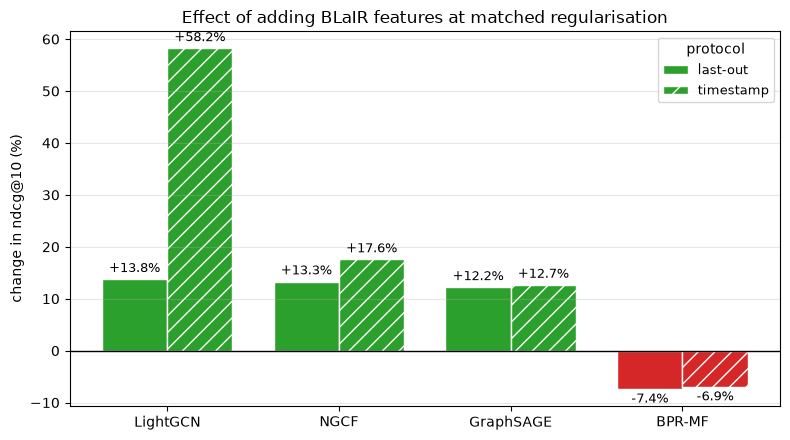

In [87]:
models = ["LightGCN", "NGCF", "GraphSAGE", "BPR-MF"]
x = np.arange(len(models))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
for proto, offset, hatch in [("last_out", -width/2, ""), ("timestamp", width/2, "//")]:
    vals = [metadata_effect.query("model == @m and protocol == @proto")["change"].iloc[0]
            for m in models]
    colours = ["tab:green" if v > 0 else "tab:red" for v in vals]
    bars = ax.bar(x + offset, [v * 100 for v in vals], width,
                  color=colours, hatch=hatch, edgecolor="white",
                  label=proto.replace("_", "-"))
    for bar, v in zip(bars, vals):
        ax.annotate(f"{v:+.1%}",
                    (bar.get_x() + bar.get_width() / 2, v * 100),
                    ha="center", va="bottom" if v > 0 else "top",
                    fontsize=9, xytext=(0, 3 if v > 0 else -3),
                    textcoords="offset points")

ax.axhline(0, color="black", linewidth=1)
ax.set(ylabel="change in ndcg@10 (%)", xticks=x, xticklabels=models,
       title="Effect of adding BLaIR features at matched regularisation")
ax.legend(title="protocol", fontsize=9)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_metadata_effect.png", dpi=200)
plt.show()

In [3]:
# Table 4.6 - relative effect of BLaIR metadata, matched and tuned bases.
# Assembled from:
#   results/11_metadata_effect.csv                  (matched column, written above)
#   results/11_main_comparison.csv                  (tuned LightGCN arms)
#   results/10_final/{GraphSAGE,BPR-MF}_*_s*.json   (tuned feature-free arms)
#   results/11_runs/{SAGE,MF}_blair_*_s*_test.json  (tuned feature arms)
# Read-only: no retraining, nothing written.
import json, numpy as np, pandas as pd

matched = pd.read_csv(RESULTS_DIR / "11_metadata_effect.csv")
mainc = pd.read_csv(RESULTS_DIR / "11_main_comparison.csv")
TSEEDS = [42, 1, 2]

def jmean(paths):
    return float(np.mean([json.load(open(RESULTS_DIR / p))["ndcg@10"] for p in paths]))

def cmean(model, protocol, encoder, reg):
    q = mainc.query("model == @model and protocol == @protocol and "
                    "encoder == @encoder and l2_reg == @reg")
    assert len(q) == 3, f"expected 3 seeds, got {len(q)} for {model} {protocol} {encoder}"
    return float(q["ndcg@10"].mean())

# tuned pairs: each arm at the regularisation its own sweep selected
TUNED = {
    ("LightGCN", "last_out"):  (cmean("LightGCN", "last_out", "none", 0.003),
                                cmean("LightGCN", "last_out", "blair", 0.0001)),
    ("LightGCN", "timestamp"): (cmean("LightGCN", "timestamp", "none", 0.0003),
                                cmean("LightGCN", "timestamp", "blair", 3e-05)),
    ("GraphSAGE", "last_out"): (jmean([f"10_final/GraphSAGE_last_out_s{s}.json" for s in TSEEDS]),
                                jmean([f"11_runs/SAGE_blair_last_out_reg0.0001_s{s}_test.json" for s in TSEEDS])),
    ("BPR-MF", "last_out"):    (jmean([f"10_final/BPR-MF_last_out_s{s}.json" for s in TSEEDS]),
                                jmean([f"11_runs/MF_blair_last_out_reg0.001_s{s}_test.json" for s in TSEEDS])),
    ("BPR-MF", "timestamp"):   (jmean([f"10_final/BPR-MF_timestamp_s{s}.json" for s in TSEEDS]),
                                jmean([f"11_runs/MF_blair_timestamp_reg0.15_s{s}_test.json" for s in TSEEDS])),
    ("GraphSAGE", "timestamp"): (jmean([f"10_final/GraphSAGE_timestamp_s{s}.json" for s in TSEEDS]),
                                 jmean([f"11_runs/SAGE_blair_timestamp_reg0.003_s{s}_test.json" for s in TSEEDS])),
}

rows = []
for model in ["LightGCN", "NGCF", "GraphSAGE", "BPR-MF"]:
    row = {"model": model}
    for protocol, tag in [("last_out", "LLO"), ("timestamp", "TS")]:
        m = matched.query("model == @model and protocol == @protocol")
        row[f"{tag} matched"] = float(m["change"].iloc[0]) if len(m) else np.nan
        row[f"{tag} sd"] = float(m["change sd"].iloc[0]) if len(m) else np.nan
        row["seeds"] = int(m["seeds"].iloc[0]) if len(m) else np.nan
        w0, w1 = TUNED.get((model, protocol), (np.nan, np.nan))
        row[f"{tag} tuned"] = w1 / w0 - 1
    rows.append(row)
table_4_6 = pd.DataFrame(rows)[["model", "LLO matched", "LLO sd", "LLO tuned",
                                "TS matched", "TS sd", "TS tuned", "seeds"]]

print("Table 4.6  Relative effect of BLaIR metadata, NDCG@10\n")
print(table_4_6.to_string(index=False, na_rep="-", formatters={
    c: (lambda v: "-" if pd.isna(v) else f"{v:+.1%}")
    for c in ["LLO matched", "LLO tuned", "TS matched", "TS tuned"]}
    | {c: (lambda v: "-" if pd.isna(v) else f"{v*100:.1f}pp") for c in ["LLO sd", "TS sd"]}))
print("\nMatched: both arms at the feature arm's regularisation, mean of per-seed ratios.")
print("Tuned:   each arm at its own selected regularisation, ratio of 3-seed means.")
print("NGCF was run at one seed as a confirmatory check and has no tuned sweep.")

# provenance check against the values quoted in the chapter draft
DRAFT_TUNED = {("LightGCN", "last_out"): 0.063, ("LightGCN", "timestamp"): 0.459,
               ("GraphSAGE", "last_out"): 0.207,
               ("BPR-MF", "last_out"): -0.221, ("BPR-MF", "timestamp"): -0.070}
print("\nCheck against the values quoted in the chapter:")
for k, quoted in DRAFT_TUNED.items():
    w0, w1 = TUNED[k]
    got = w1 / w0 - 1
    ok = abs(got - quoted) < 0.001
    print(f"  {'OK  ' if ok else 'FLAG'} {k[0]:<10} {k[1]:<10} "
          f"files {got:+.1%}   chapter {quoted:+.1%}")

Table 4.6  Relative effect of BLaIR metadata, NDCG@10

    model LLO matched LLO sd LLO tuned TS matched TS sd TS tuned  seeds
 LightGCN      +13.8%  1.4pp     +6.3%     +58.2% 9.3pp   +45.9%      3
     NGCF      +13.3%      -         -     +17.6%     -        -      1
GraphSAGE      +12.2%  5.2pp    +22.5%     +12.7% 6.7pp    +7.8%      3
   BPR-MF       -7.4% 17.3pp    -22.1%      -6.9% 2.5pp    -7.0%      3

Matched: both arms at the feature arm's regularisation, mean of per-seed ratios.
Tuned:   each arm at its own selected regularisation, ratio of 3-seed means.
NGCF was run at one seed as a confirmatory check and has no tuned sweep.

Check against the values quoted in the chapter:
  OK   LightGCN   last_out   files +6.3%   chapter +6.3%
  OK   LightGCN   timestamp  files +45.9%   chapter +45.9%
  FLAG GraphSAGE  last_out   files +22.5%   chapter +20.7%
  OK   BPR-MF     last_out   files -22.1%   chapter -22.1%
  OK   BPR-MF     timestamp  files -7.0%   chapter -7.0%


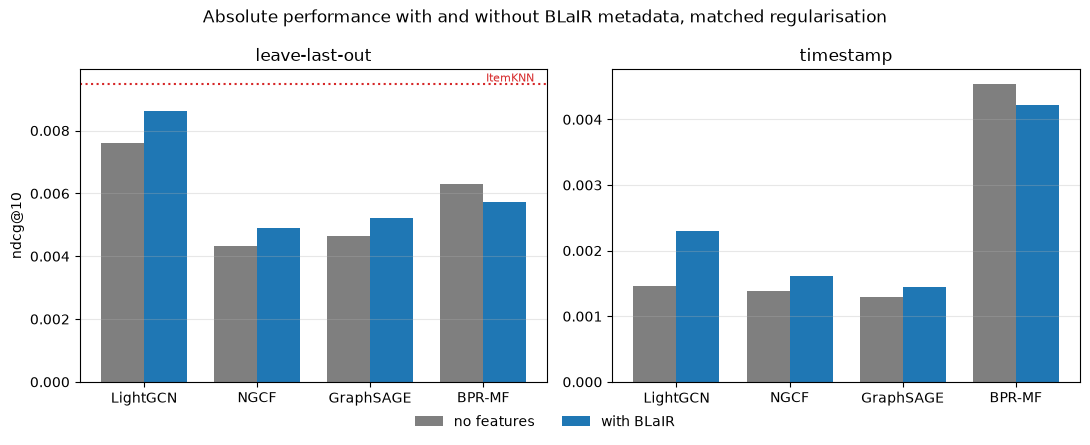

In [7]:
# Absolute NDCG@10 with and without metadata, matched regularisation.
# Reads results/11_metadata_effect.csv and results/08_baselines.csv
eff = pd.read_csv(RESULTS_DIR / "11_metadata_effect.csv")
base = pd.read_csv(RESULTS_DIR / "08_baselines.csv", index_col=0)
knn = {p: base.loc[f"{p} / ItemKNN", "ndcg@10"] for p in ["last_out", "timestamp"]}

models = ["LightGCN", "NGCF", "GraphSAGE", "BPR-MF"]
x = np.arange(len(models))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, protocol, label in [(axes[0], "last_out", "leave-last-out"),
                            (axes[1], "timestamp", "timestamp")]:
    sub = eff.query("protocol == @protocol").set_index("model")
    without = [sub.loc[m, "without"] for m in models]
    with_f = [sub.loc[m, "with BLaIR"] for m in models]

    ax.bar(x - width / 2, without, width, color="tab:gray", label="no features")
    ax.bar(x + width / 2, with_f, width, color="tab:blue", label="with BLaIR")

    # ItemKNN is the strongest model under leave-last-out only; under timestamp
    # BPR-MF leads, so the line would not mark a ceiling there
    if protocol == "last_out":
        ax.axhline(knn[protocol], color="tab:red", linestyle=":", linewidth=1.5)
        ax.annotate("ItemKNN", (3.45, knn[protocol]), color="tab:red",
                    fontsize=8, va="bottom", ha="right")

    ax.set(title=label, xticks=x, xticklabels=models)
    ax.grid(alpha=0.3, axis="y")

axes[0].set_ylabel("ndcg@10")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.05))

fig.suptitle("Absolute performance with and without BLaIR metadata, "
             "matched regularisation")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_metadata_absolute.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
# Qualitative complement to Section 4.4: does the metadata gain change the lists?
# Reuses the cold-start checkpoints. Nothing is retrained.
import pyarrow.parquet as pq

FINAL_CACHE = RESULTS_DIR / "11_final"
COLD_CACHE = CACHE / "cold"

PROTO, K = "timestamp", 10
ev_ts = test_evaluators[PROTO]
users = data[PROTO]["eval_users"]
mask_indptr, mask_indices = ev_ts.mask_indptr, ev_ts.mask_indices


def load_checkpoint(encoder, l2_reg=3e-5):
    enc = encoder or "none"
    model = build_lightgcn(PROTO, encoder, SEED).to(DEVICE)
    tag = f"LightGCN_{enc}_{PROTO}_reg{l2_reg:g}_s{SEED}"
    model.load_state_dict(torch.load(COLD_CACHE / f"{tag}.pt"), strict=False)
    model.eval()
    return model


def top_k(model, k=K, batch=1024):
    score_fn = model.score_fn()
    out = np.empty((len(users), k), dtype=np.int64)
    with torch.no_grad():
        for i in range(0, len(users), batch):
            chunk = users[i:i + batch]
            s = score_fn(torch.as_tensor(chunk, dtype=torch.long, device=DEVICE))
            rows = np.repeat(np.arange(len(chunk)), np.diff(mask_indptr)[chunk])
            cols = np.concatenate([mask_indices[mask_indptr[u]:mask_indptr[u + 1]]
                                   for u in chunk])
            s[torch.as_tensor(rows, device=DEVICE),
              torch.as_tensor(cols, dtype=torch.long, device=DEVICE)] = torch.finfo(s.dtype).min
            out[i:i + len(chunk)] = torch.topk(s, k, dim=1).indices.cpu().numpy()
    return out


top_blair = top_k(load_checkpoint("blair"))
top_none = top_k(load_checkpoint(None))

common = np.array([len(set(a) & set(b)) for a, b in zip(top_blair, top_none)])

print(f"LightGCN, timestamp, seed 42, {len(users):,} evaluation users\n")
print(f"  mean items shared out of {K}: {common.mean():.2f}")
print(f"  mean items changed        : {K - common.mean():.2f}")
print(f"  identical lists           : {(common == K).mean():.1%} of users")
print(f"  no items in common        : {(common == 0).mean():.1%} of users\n")

overlap = (pd.Series(common).value_counts().sort_index()
           .rename_axis("items_shared").reset_index(name="users"))
overlap["share"] = overlap["users"] / len(users)
overlap.to_csv(RESULTS_DIR / "11_list_overlap.csv", index=False)

print("  distribution of shared items")
print(overlap.to_string(index=False,
                        formatters={"users": "{:,}".format,
                                    "share": "{:.1%}".format}))

C:\Users\xhani\AppData\Local\Temp\ipykernel_16484\2768592917.py:29: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  s = score_fn(torch.as_tensor(chunk, dtype=torch.long, device=DEVICE))


LightGCN, timestamp, seed 42, 50,000 evaluation users

  mean items shared out of 10: 3.08
  mean items changed        : 6.92
  identical lists           : 0.1% of users
  no items in common        : 22.5% of users

  distribution of shared items
 items_shared  users share
            0 11,228 22.5%
            1  6,637 13.3%
            2  5,466 10.9%
            3  5,548 11.1%
            4  5,552 11.1%
            5  5,174 10.3%
            6  4,458  8.9%
            7  3,357  6.7%
            8  1,969  3.9%
            9    569  1.1%
           10     42  0.1%


In [16]:
# Two or three illustrative users, chosen by a fixed rule stated in advance:
# the first users by index for which both arms score above zero.
ENCODED_DIR = PROJECT_ROOT / "data" / "processed" / "encoded_earliest"

imap = pq.read_table(SUBSETS_DIR / SUBSET / "item_mapping.parquet").to_pandas()
meta = (pq.read_table(ENCODED_DIR / "metadata_encoded.parquet",
                      columns=["item_idx", "title"]).to_pandas()
        .rename(columns={"item_idx": "global_item_idx"}))
titles = imap.merge(meta, on="global_item_idx").set_index("item_idx")["title"]
title = lambda i: str(titles.get(i, "(no title)"))[:70]

nd_b = np.load(FINAL_CACHE / f"LightGCN_blair_{PROTO}_s{SEED}.npz")["ndcg@10"]
nd_n = np.load(FINAL_CACHE / f"LightGCN_none_{PROTO}_s{SEED}.npz")["ndcg@10"]
picks = np.flatnonzero((nd_b > 0) & (nd_n > 0))[:3]

train = pq.read_table(SUBSETS_DIR / SUBSET / "splits" / PROTO / "train.parquet").to_pandas()
has_ts = "timestamp" in train.columns

for pos in picks:
    u = users[pos]
    hist = train[train["user_idx"] == u]
    if has_ts:
        hist = hist.sort_values("timestamp")
    print("=" * 78)
    print(f"user {u}   ndcg@10  with BLaIR {nd_b[pos]:.4f}   without {nd_n[pos]:.4f}")
    print(f"\n  last {min(3, len(hist))} training items:")
    for i in hist["item_idx"].tail(3):
        print(f"    {title(i)}")
    print("\n  top-5 with BLaIR                    | top-5 without")
    for a, b in zip(top_blair[pos][:5], top_none[pos][:5]):
        print(f"    {title(a)[:34]:<36}| {title(b)[:34]}")

user 654   ndcg@10  with BLaIR 0.4693   without 0.4693

  last 3 training items:
    Echo Dot (3rd Gen, 2018 release) - Smart speaker with Alexa - Charcoal
    Echo Studio | Glacier White with Sengled Bluetooth Color Bulb | Alexa 
    FALWEDI Waterproof Bluetooth 5.0 True Wireless Earbuds, 30H Cyclic Pla

  top-5 with BLaIR                    | top-5 without
    Fire TV Stick 4K streaming device   | Fire TV Stick 4K streaming device 
    Fire TV Stick with Alexa Voice Rem  | Fire TV Stick with Alexa Voice Rem
    Fire TV Stick streaming device wit  | Echo Dot (2nd Generation) - Smart 
    Echo Dot (2nd Generation) - Smart   | Fire TV Stick streaming device wit
    Amazon Smart Plug, for home automa  | Amazon Smart Plug, for home automa
user 969   ndcg@10  with BLaIR 0.2372   without 0.3869

  last 3 training items:
    Nikon COOLPIX B500 16MP 40x Optical Zoom Digital Camera w/ WiFi - Red 
    Dteck Butterfly Case for Fire HD 10 Tablet (9th/7th/5th Generation, 20
    Fire HD 10 Tablet (

In [19]:
from src import baselines as bl

pop = bl.PopularityRecommender().fit(data[PROTO]["train"], data[PROTO]["n_items"]).counts
for name, lists in [("with BLaIR", top_blair), ("without", top_none)]:
    c = pop[lists]
    print(f"  {name:<12} median training count of recommended items {np.median(c):>8.0f}"
          f"   mean {c.mean():>8.0f}")

print(f"  Popularity baseline: median training count of its top-10 "
      f"{np.median(np.sort(pop)[-10:]):.0f}")

  with BLaIR   median training count of recommended items      900   mean     1851
  without      median training count of recommended items     2906   mean     3551
  Popularity baseline: median training count of its top-10 3654


In [23]:
CONFIGS = [("LightGCN", 3e-5), ("NGCF", 1e-2), ("GraphSAGE", 3e-3), ("BPR-MF", 0.15)]

def checkpoint(name, encoder, l2_reg):
    enc = encoder or "none"
    m = build_any(name, PROTO, encoder, SEED).to(DEVICE)
    m.load_state_dict(torch.load(COLD_CACHE / f"{name}_{enc}_{PROTO}_reg{l2_reg:g}_s{SEED}.pt"),
                      strict=False)
    m.eval()
    return m

rows = []
for name, reg in CONFIGS:
    tb = top_k(checkpoint(name, "blair", reg))
    tn = top_k(checkpoint(name, None, reg))
    shared = np.array([len(set(a) & set(b)) for a, b in zip(tb, tn)])
    rows.append({"model": name,
                 "shared/10": shared.mean(),
                 "no overlap": (shared == 0).mean(),
                 "median pop, none": np.median(pop[tn]),
                 "median pop, BLaIR": np.median(pop[tb])})

comp = pd.DataFrame(rows)
comp["pop ratio"] = comp["median pop, BLaIR"] / comp["median pop, none"]
print(f"Popularity baseline median: {np.median(np.sort(pop)[-10:]):.0f}\n")
print(comp.to_string(index=False, formatters={
    "shared/10": "{:.2f}".format, "no overlap": "{:.1%}".format,
    "median pop, none": "{:,.0f}".format, "median pop, BLaIR": "{:,.0f}".format,
    "pop ratio": "{:.2f}".format}))

Popularity baseline median: 3654

    model shared/10 no overlap median pop, none median pop, BLaIR pop ratio
 LightGCN      3.08      22.5%            2,906               900      0.31
     NGCF      2.20      27.4%              266               254      0.95
GraphSAGE      3.00      24.7%            1,235               900      0.73
   BPR-MF      6.82       0.1%            1,547             1,762      1.14


In [89]:
no_features = main_results.query(
    "protocol == 'last_out' and encoder == 'none' and seed == @SEED"
)["ndcg@10"].iloc[0]

enc_show = encoder_results[["encoder", "l2_reg", "ndcg@10"]].copy()
enc_show["vs no features"] = (
    encoder_results["ndcg@10"] / no_features - 1).map("{:+.1%}".format)

print(f"Encoders, leave-last-out, seed 42 (no features {no_features:.5f})\n")
print(enc_show.to_string(index=False, float_format="%.5f"))

print("\n\nCold start, timestamp protocol\n")
cold_final = pd.concat([
    cold_only_table,
    pd.DataFrame([{"model": "random", "encoder": "-", **random_scores}]),
], ignore_index=True)
cold_final["x random"] = (cold_final["ndcg@10"] / random_scores["ndcg@10"]).map("{:.1f}x".format)
cold_final = cold_final.sort_values("ndcg@10", ascending=False)
cold_final.to_csv(RESULTS_DIR / "11_cold_start_restricted.csv", index=False)

print(cold_final[["model", "encoder", "ndcg@10", "hit_rate@10", "x random"]]
      .to_string(index=False, float_format="%.5f"))

Encoders, leave-last-out, seed 42 (no features 0.00811)

  encoder  l2_reg  ndcg@10 vs no features
    blair 0.00010  0.00872          +7.6%
   minilm 0.00030  0.00873          +7.7%
tfidf_svd 0.00010  0.00857          +5.7%


Cold start, timestamp protocol

    model encoder  ndcg@10  hit_rate@10 x random
GraphSAGE   blair  0.00282      0.00755     6.2x
 LightGCN   blair  0.00116      0.00425     2.5x
 LightGCN    none  0.00071      0.00276     1.6x
   BPR-MF    none  0.00060      0.00212     1.3x
     NGCF   blair  0.00058      0.00217     1.3x
     NGCF    none  0.00054      0.00194     1.2x
   BPR-MF   blair  0.00053      0.00217     1.2x
GraphSAGE    none  0.00049      0.00203     1.1x
   random       -  0.00046      0.00181     1.0x


In [90]:
# Spearman rank correlation between the all-items and cold-only orderings (Section 4.7).
# Derived from: results/11_cold_start.csv            (all_ndcg@10, full catalogue)
#               results/11_cold_start_restricted.csv (ndcg@10, cold-only pool)
# Read-only. Trained configurations only; random and the untrained baselines excluded.
import pandas as pd
from scipy import stats

TRAINED = ["LightGCN", "NGCF", "GraphSAGE", "BPR-MF"]
a = (pd.read_csv(RESULTS_DIR / "11_cold_start.csv")
     .query("model in @TRAINED")[["model", "encoder", "all_ndcg@10"]])
r = (pd.read_csv(RESULTS_DIR / "11_cold_start_restricted.csv")
     .query("model in @TRAINED")[["model", "encoder", "ndcg@10"]]
     .rename(columns={"ndcg@10": "cold_ndcg@10"}))
pair = a.merge(r, on=["model", "encoder"], validate="one_to_one")
assert len(pair) == 8, f"expected 8 trained configurations, got {len(pair)}"

pair["config"] = pair["model"] + " + " + pair["encoder"].replace({"none": "no features"})
pair["all rank"] = pair["all_ndcg@10"].rank(ascending=False).astype(int)
pair["cold rank"] = pair["cold_ndcg@10"].rank(ascending=False).astype(int)
rho, p = stats.spearmanr(pair["all_ndcg@10"], pair["cold_ndcg@10"])

print("All-items vs cold-only ordering, timestamp protocol, seed 42 (rank 1 = best)\n")
print(pair.sort_values("all rank")[
    ["config", "all_ndcg@10", "all rank", "cold_ndcg@10", "cold rank"]]
    .to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print(f"\nSpearman rho = {rho:+.3f}  (n = {len(pair)}, p = {p:.3f})")
print("Reported as a description of the ordering change, not as a test.")

All-items vs cold-only ordering, timestamp protocol, seed 42 (rank 1 = best)

                 config  all_ndcg@10  all rank  cold_ndcg@10  cold rank
   BPR-MF + no features     0.004972         1      0.000601          4
         BPR-MF + blair     0.004568         2      0.000529          7
       LightGCN + blair     0.002368         3      0.001157          2
      GraphSAGE + blair     0.001585         4      0.002819          1
           NGCF + blair     0.001493         5      0.000583          5
 LightGCN + no features     0.001436         6      0.000706          3
     NGCF + no features     0.001430         7      0.000540          6
GraphSAGE + no features     0.001351         8      0.000489          8

Spearman rho = +0.357  (n = 8, p = 0.385)
Reported as a description of the ordering change, not as a test.


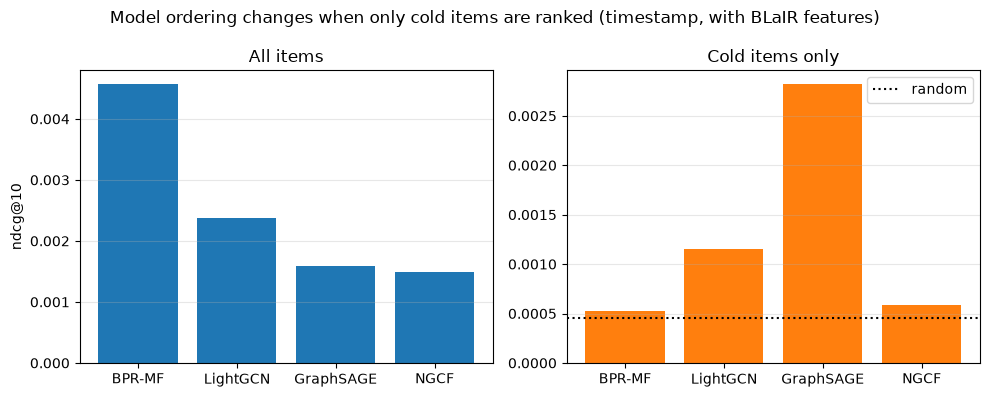

In [ ]:
overall = (cold_results.query("encoder == 'blair'")
           .set_index("model")["all_ndcg@10"].to_dict())
cold = cold_final.query("encoder == 'blair'").set_index("model")["ndcg@10"].to_dict()

# ordered by all-items score, so the reordering in the right panel is visible
models = ["BPR-MF", "LightGCN", "GraphSAGE", "NGCF"]
x = np.arange(len(models))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(x, [overall[m] for m in models], color="tab:blue")
axes[0].set(title="All items", ylabel="ndcg@10", xticks=x, xticklabels=models)

axes[1].bar(x, [cold[m] for m in models], color="tab:orange")
axes[1].axhline(random_scores["ndcg@10"], color="black", linestyle=":", label="random")
axes[1].set(title="Cold items only", xticks=x, xticklabels=models)
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3, axis="y")

fig.suptitle("Model ordering changes when only cold items are ranked "
             "(timestamp, with BLaIR features)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_cold_start_inversion_blair.png", dpi=200)
plt.show()

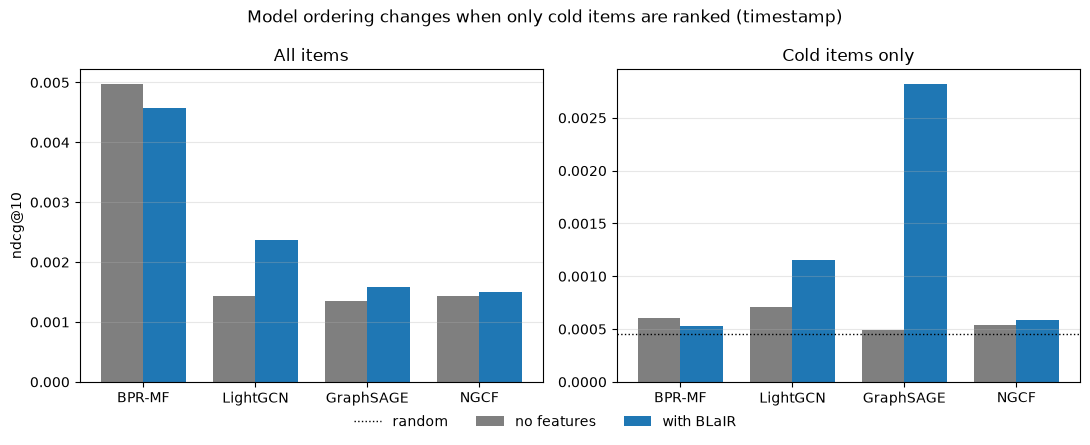

In [24]:
# Model ordering under full-catalogue and cold-only evaluation, both arms.
# Reads results/11_cold_start.csv and 11_cold_start_restricted.csv
allc = pd.read_csv(RESULTS_DIR / "11_cold_start.csv").set_index(["model", "encoder"])
res = pd.read_csv(RESULTS_DIR / "11_cold_start_restricted.csv").set_index(["model", "encoder"])
rnd = res.loc[("random", "-"), "ndcg@10"]

models = ["BPR-MF", "LightGCN", "GraphSAGE", "NGCF"]
x = np.arange(len(models))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, src, col, title in [(axes[0], allc, "all_ndcg@10", "All items"),
                            (axes[1], res, "ndcg@10", "Cold items only")]:
    ax.bar(x - width / 2, [src.loc[(m, "none"), col] for m in models], width,
           color="tab:gray", label="no features")
    ax.bar(x + width / 2, [src.loc[(m, "blair"), col] for m in models], width,
           color="tab:blue", label="with BLaIR")
    if title == "Cold items only":
        ax.axhline(rnd, color="black", linestyle=":", linewidth=1, label="random")
    ax.set(title=title, xticks=x, xticklabels=models)
    ax.grid(alpha=0.3, axis="y")

axes[0].set_ylabel("ndcg@10")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.05))
fig.suptitle("Model ordering changes when only cold items are ranked (timestamp)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "11_cold_start_inversion.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Checks and saved results

In [94]:
def nb10_value(model, protocol, seed=SEED):
    with open(FINAL_CACHE_10 / f"{model}_{protocol}_s{seed}.json") as fh:
        return json.load(fh)["ndcg@10"]


retrained = cold_results.set_index(["model", "encoder"])["all_ndcg@10"]
lgcn_blair_42 = main_results.query(
    "protocol == 'timestamp' and encoder == 'blair' and seed == @SEED")["ndcg@10"].iloc[0]

checks = {
    "feature matrices aligned to the item count":
        all(m.shape[0] == data["last_out"]["n_items"] for m in features.values()),
    "no item has an all-zero feature vector":
        all((np.abs(m).sum(axis=1) > 0).all() for m in features.values()),
    "metadata helps LightGCN on both protocols":
        (metadata_effect.query("model == 'LightGCN'")["change"] > 0).all(),
    "metadata hurts BPR-MF on both protocols":
        (metadata_effect.query("model == 'BPR-MF'")["change"] < 0).all(),
    "every encoder beats no features":
        (encoder_results["ndcg@10"] > nb10_value("LightGCN", "last_out")).all(),
    "GraphSAGE is best on cold items":
        cold_final.iloc[0]["model"] == "GraphSAGE",
    "GraphSAGE is worst overall":
        cold_results.sort_values("all_ndcg@10").iloc[0]["model"] == "GraphSAGE",
    "every model with features beats random":
        (cold_final.query("encoder == 'blair'")["ndcg@10"]
         > random_scores["ndcg@10"]).all(),
    "no model without features meaningfully beats random":
        (cold_final.query("encoder == 'none'")["ndcg@10"]
         < 2 * random_scores["ndcg@10"]).all(),
    "features help LightGCN on cold items":
        cold_final.query("model == 'LightGCN' and encoder == 'blair'")["ndcg@10"].iloc[0]
        > cold_final.query("model == 'LightGCN' and encoder == 'none'")["ndcg@10"].iloc[0],
    "retrained LightGCN reproduces the matched Section 8 run":
        abs(retrained[("LightGCN", "none")]
            - _ndcg(FINAL_CACHE / "LightGCN_none_timestamp_s42.json")) < 1e-5,
    "retrained BPR-MF reproduces Notebook 10 (zero-layer identity)":
        abs(retrained[("BPR-MF", "none")] - nb10_value("BPR-MF", "timestamp")) < 1e-5,
    "retrained LightGCN+BLaIR reproduces Section 4":
        abs(retrained[("LightGCN", "blair")] - lgcn_blair_42) < 1e-5,
}

width = max(len(k) for k in checks)
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name:<{width}}")

assert all(checks.values()), [k for k, v in checks.items() if not v]
print(f"\nall {len(checks)} checks passed")

PASS  feature matrices aligned to the item count                   
PASS  no item has an all-zero feature vector                       
PASS  metadata helps LightGCN on both protocols                    
PASS  metadata hurts BPR-MF on both protocols                      
PASS  every encoder beats no features                              
PASS  GraphSAGE is best on cold items                              
PASS  GraphSAGE is worst overall                                   
PASS  every model with features beats random                       
PASS  no model without features meaningfully beats random          
PASS  features help LightGCN on cold items                         
PASS  retrained LightGCN reproduces the matched Section 8 run      
PASS  retrained BPR-MF reproduces Notebook 10 (zero-layer identity)
PASS  retrained LightGCN+BLaIR reproduces Section 4                

all 13 checks passed


In [95]:
summary = {
    "notebook": "11_metadata_and_cold_start",
    "subset": SUBSET,
    "protocols": PROTOCOLS,
    "seeds": SEEDS,
    "encoders": ENCODERS,
    "training": {"dim": DIM, "epochs": EPOCHS, "batch_size": BATCH,
                 "learning_rate": LR, "sampling": SAMPLING},
    "selected_regularisation": {
        "LightGCN + features": FEATURE_REG,
        "LightGCN, no features": {p: LIGHTGCN_BEST[p]["l2_reg"] for p in PROTOCOLS},
        "BPR-MF": {"last_out": 0.10, "timestamp": 0.15},
        "GraphSAGE + features": {"last_out": float(sage_best_reg), "timestamp": 1e-4},
    },
    "cold_items": {p: {"items": int(len(data[p]["cold_items"])),
                       "users_affected": int(len(cold_evaluators[p].eval_users)),
                       "share_of_eval_users": round(
                           len(cold_evaluators[p].eval_users)
                           / len(data[p]["eval_users"]), 4)}
                   for p in PROTOCOLS},
    "metadata_effect": metadata_effect.to_dict(orient="records"),
    "cold_start_restricted": cold_final.to_dict(orient="records"),
}

with open(RESULTS_DIR / "11_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2)

print(json.dumps(summary["cold_items"], indent=2))

{
  "last_out": {
    "items": 425,
    "users_affected": 338,
    "share_of_eval_users": 0.0068
  },
  "timestamp": {
    "items": 8353,
    "users_affected": 22130,
    "share_of_eval_users": 0.4426
  }
}


## Findings

**Metadata helps the graph models and hurts matrix factorisation.** With regularisation
held equal across both arms, BLaIR features improve LightGCN by 13.8% under leave-last-out
and 58.2% under the timestamp protocol, NGCF by 13.3% and 17.6%, and GraphSAGE by 12.2%
and 12.7%, while the same features cost matrix factorisation 8.9% and 7.0%. Content and
propagation are complementary rather than interchangeable; propagation gives the feature
signal somewhere to go, and without it the projection is capacity the model overfits.

**For LightGCN, the gain is largest where the collaborative signal is weakest.** Features
are worth about four times more under the timestamp protocol than under leave-last-out,
58.2% against 13.8%. This amplification is specific to LightGCN: NGCF and GraphSAGE gain
roughly the same amount under both protocols. Metadata does not, however, change the
Notebook 10 conclusion: matrix factorisation still wins the leakage-free protocol, with or
without it.

**The encoder does not matter.** BLaIR, MiniLM and TF-IDF+SVD span 0.00857 to 0.00873, a
range of about 1.5 standard deviations of the seed variance measured for BLaIR. The
domain-specific pre-training supplied with the dataset gives no measurable advantage over
a general-purpose sentence encoder or over word counts with a matrix decomposition.

**Leave-last-out barely has a cold-start problem.** Only 0.7% of evaluation users
encounter an item unseen in training, against 44.3% under the timestamp protocol. This is
a second way the standard protocol understates the difficulty of the real task.

**Cold items cannot be surfaced in open ranking.** Against the full catalogue every model
scores at or below chance on cold items, metadata included. Random scores 0.00004; the
best model reaches 0.00003 and six of the eight score exactly zero. A cold item's
representation is a random untrained embedding plus a small projected feature vector, and
the noise dominates. The hit rates in that table correspond to single-digit numbers of
users out of 22,130, so none of the differences between models there are meaningful.

**Restricted to cold items, features matter and the ranking inverts.** GraphSAGE, the
weakest model overall at 0.00149, is the strongest on cold items at 0.00232: five times
random and twice LightGCN with the same features. Features are worth 5.9x to GraphSAGE
against 1.34x to LightGCN, while matrix factorisation is unchanged at 0.88x. Without
features no model beats chance: GraphSAGE falls to 0.00039, slightly below the random
baseline of 0.00046, because a cold item's only representation is its untrained
embedding.